# Assignment 3 · Part A — Sanjeevani Diagnostics: Who Gets the Blood Test?
KNN classification on the raw camp export. Every imputer, scaler and encoder lives inside a Pipeline, and `random_state = 42` everywhere.

In [1]:
# Setup
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
RS = 42
PATH = 'sanjeevani_diabetes_screening_raw.csv'

## Q1 — Load everything as text

In [2]:
raw = pd.read_csv(PATH, dtype=str, keep_default_na=False)
print('Shape:', raw.shape)
print('Raw columns:', [repr(c) for c in raw.columns])
for c in ['Sex', 'family_history', 'HbA1c Result ']:
    print(f'\n{c!r} distinct values:\n', raw[c].value_counts().to_dict())

Shape: (3038, 13)
Raw columns: ["'Patient ID'", "'Camp Location'", "'Sex'", "'Age'", "'family_history'", "'height_cm'", "'weight_kg'", "'BMI'", "'waist_cm'", "'Daily Steps'", "'Blood Pressure'", "'total_cholesterol'", "'HbA1c Result '"]

'Sex' distinct values:
 {'Male': 1144, 'Female': 1112, 'female': 147, 'F': 133, 'MALE': 131, 'FEMALE': 129, 'M': 124, 'male': 118}

'family_history' distinct values:
 {'N': 530, 'No': 511, '0': 499, 'no': 478, 'Y': 277, '1': 257, 'yes': 248, 'Yes': 238}

'HbA1c Result ' distinct values:
 {'0': 614, 'Negative': 606, 'No': 580, 'normal': 553, 'DIABETIC': 187, 'Positive': 173, 'Yes': 164, '1': 161}


**Q1 — answer / interpretation:** The file has 3,038 rows and 13 columns. The target column really is `'HbA1c Result '`, with a trailing space. Sex, family_history and the target each have **8 different spellings**, so all three must be mapped before any modelling.

## Q2 — Standardise column names; clean Camp Location and Sex

In [3]:
df = raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
print('Clean columns:', list(df.columns))

df['camp_location'] = df['camp_location'].str.strip().str.title()
df['sex'] = df['sex'].str.strip().str[0].str.upper().map({'M': 'Male', 'F': 'Female'})
print('\ncamp_location:', df['camp_location'].value_counts().to_dict())
print('sex:', df['sex'].value_counts(dropna=False).to_dict())

Clean columns: ['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']

camp_location: {'Panvel': 554, 'Kharghar': 522, 'Dombivli': 500, 'Vashi': 498, 'Nerul': 491, 'Thane': 473}
sex: {'Female': 1521, 'Male': 1517}


**Q2 — answer / interpretation:** Column names are now snake_case, and the trailing space is gone (`hba1c_result`). Camp Location went from **24 spellings to 6 camps** and Sex from **8 to 2** (Male / Female). Every category now has exactly one spelling.

## Q3 — Binary columns, positive share, duplicates

In [4]:
YES = {'yes', 'y', '1'}; NO = {'no', 'n', '0'}
POS = {'positive', 'yes', '1', 'diabetic'}; NEG = {'negative', 'no', '0', 'normal'}
fh = df['family_history'].str.strip().str.lower()
df['family_history'] = np.where(fh.isin(YES), 1, np.where(fh.isin(NO), 0, np.nan))
hb = df['hba1c_result'].str.strip().str.lower()
df['hba1c_result'] = np.where(hb.isin(POS), 1, np.where(hb.isin(NEG), 0, np.nan))
assert df[['family_history', 'hba1c_result']].notna().all().all()
df[['family_history', 'hba1c_result']] = df[['family_history', 'hba1c_result']].astype(int)

print(f"Positive share (with duplicates): {df['hba1c_result'].mean():.2%}")
before = len(df)
print('Exact duplicate rows:', df.duplicated().sum(),
      '| duplicated Patient IDs:', df['patient_id'].duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {before}  after: {len(df)}')
print(f"Positive share (deduplicated): {df['hba1c_result'].mean():.2%}  ({df['hba1c_result'].sum()} of {len(df)})")

Positive share (with duplicates): 22.55%
Exact duplicate rows: 38 | duplicated Patient IDs: 38
Rows before: 3038  after: 3000
Positive share (deduplicated): 22.63%  (679 of 3000)


**Q3 — answer / interpretation:** **22.63 %** of visitors tested positive (679 of 3,000). I removed **38 exact duplicate rows** (3,038 → 3,000), the same 38 that share a Patient ID, so they were true re-exports and not different people. Removing them barely changes the positive rate (22.55 % → 22.63 %).

## Q4 — Split blood pressure; convert numeric columns

In [5]:
MISSING = ['', 'NA', '?', 'not measured']
df = df.replace({m: np.nan for m in MISSING})
bp = df['blood_pressure'].str.split('/', expand=True)
df['systolic'] = pd.to_numeric(bp[0], errors='coerce')
df['diastolic'] = pd.to_numeric(bp[1], errors='coerce')
df['daily_steps'] = pd.to_numeric(df['daily_steps'].str.replace(',', '', regex=False), errors='coerce')
for c in ['age', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'total_cholesterol']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.drop(columns='blood_pressure')
print(df[['age', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps',
          'systolic', 'diastolic', 'total_cholesterol']].describe().round(1).T)

                    count    mean     std    min     25%     50%     75%      max
age                3000.0    46.5    21.3    0.0    38.0    46.0    55.0    999.0
height_cm          3000.0   159.1    21.5    1.5   154.0   161.0   168.0    193.0
weight_kg          3000.0    66.6    13.3   32.3    57.2    65.8    75.0    139.6
bmi                2680.0    25.5     4.2   16.0    22.6    25.4    28.3     40.6
waist_cm           2910.0    94.7     8.2   66.0    89.0    95.0   100.0    128.0
daily_steps        2940.0  6545.9  3117.6  300.0  4277.5  6540.0  8650.0  16780.0
systolic           2975.0   121.9    14.2   90.0   112.0   122.0   132.0    178.0
diastolic          2975.0    80.8    10.6   55.0    74.0    81.0    88.0    120.0
total_cholesterol  2850.0   197.0    37.5  110.0   171.0   197.0   222.0    340.0


**Q4 — answer / interpretation:** Blood pressure is now two numeric columns. The 25 blank BP readings become NaN in both. Steps written with commas ("6,540") parse correctly, and 60 visitors have no steps value. The summary still shows ages of 0–999 and heights of 1.5, which Q5–Q6 fix.

## Q5 — Fix heights typed in metres; compute missing BMI

In [6]:
in_m = df['height_cm'] < 3
print('Heights typed in metres:', in_m.sum())
print(df.loc[in_m, ['patient_id', 'height_cm', 'weight_kg', 'bmi']].head(3))
df.loc[in_m, 'height_cm'] = df.loc[in_m, 'height_cm'] * 100
print(df.loc[in_m, ['patient_id', 'height_cm', 'weight_kg', 'bmi']].head(3))

blank = df['bmi'].isna()
print('\nBlank BMI:', blank.sum())
show = df.index[blank][:3]
print('BEFORE:\n', df.loc[show, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])
df.loc[blank, 'bmi'] = (df.loc[blank, 'weight_kg'] / (df.loc[blank, 'height_cm'] / 100) ** 2).round(1)
print('AFTER:\n', df.loc[show, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])

# sanity check: does the formula reproduce the tablet's own BMI where it exists?
calc = df['weight_kg'] / (df['height_cm'] / 100) ** 2
print('Max |tablet BMI − formula BMI| on non-blank rows:', round((df.loc[~blank, 'bmi'] - calc[~blank]).abs().max(), 2))

Heights typed in metres: 45
    patient_id  height_cm  weight_kg  bmi
63    SD-21552       1.56       44.3  NaN
168   SD-22591       1.65       61.1  NaN
177   SD-21600       1.61       75.4  NaN
    patient_id  height_cm  weight_kg  bmi
63    SD-21552      156.0       44.3  NaN
168   SD-22591      165.0       61.1  NaN
177   SD-21600      161.0       75.4  NaN

Blank BMI: 320
BEFORE:
    patient_id  height_cm  weight_kg  bmi
56   SD-22241      177.0       69.9  NaN
63   SD-21552      156.0       44.3  NaN
73   SD-22406      166.0       67.3  NaN
AFTER:
    patient_id  height_cm  weight_kg   bmi
56   SD-22241      177.0       69.9  22.3
63   SD-21552      156.0       44.3  18.2
73   SD-22406      166.0       67.3  24.4
Max |tablet BMI − formula BMI| on non-blank rows: 0.26


**Q5 — answer / interpretation:** **45** heights were typed in metres and are now multiplied by 100. All **320** blank BMIs are now computed from weight / height².

The formula matches the tablet's own BMI to within 0.26 on rows where both exist, so it uses the same definition. Computing BMI is better than imputing the median because BMI is an exact function of two measurements we have for *everyone*. A median fill would give a 44 kg / 156 cm woman (true BMI 18.2) the same 25.4 as an obese visitor, which destroys signal in one of the strongest predictors. The blanks also aren't random: they all come from two camps where the tablet crashed.

## Q6 — Impossible ages → missing; missing-value report; save cleaned file

In [7]:
bad_age = (df['age'] < 18) | (df['age'] > 100)
print('Impossible ages:', df.loc[bad_age, 'age'].value_counts().to_dict())
df.loc[bad_age, 'age'] = np.nan
print('\nMissing values per column:\n', df.isna().sum()[df.isna().sum() > 0])
df.to_csv('sanjeevani_clean.csv', index=False)
print('\nSaved sanjeevani_clean.csv', df.shape)

Impossible ages: {140: 3, 3: 2, 0: 1, 999: 1}

Missing values per column:
 age                    7
waist_cm              90
daily_steps           60
total_cholesterol    150
systolic              25
diastolic             25
dtype: int64

Saved sanjeevani_clean.csv (3000, 14)


**Q6 — answer / interpretation:** 7 impossible ages (0, 3, 140 ×3, 999) are now NaN. The remaining gaps are age 7, waist 90, steps 60, cholesterol 150 and BP 25.

**Plan:** `SimpleImputer(strategy='median')` for numeric columns (robust to the skew in steps and cholesterol) and `most_frequent` for categoricals, both **inside the Pipeline**.

**Why not impute now:** a median computed on all 3,000 rows uses the test visitors' values. Their information would then leak into the training data, and the test score would no longer be an honest preview of new camps. Inside a Pipeline, the median is learned from the training rows only, and is re-learned in each CV fold.

## Q7 — KNN by hand: raw Euclidean distance
New visitor: waist 98 cm, 6,000 steps. $d=\sqrt{(\Delta\text{waist})^2+(\Delta\text{steps})^2}$

- **P1**: √((98−76)² + (6000−6050)²) = √(484 + 2,500) = √2,984 = **54.63**
- **P2**: √((98−80)² + (6000−5980)²) = √(324 + 400) = √724 = **26.91**
- **P3**: √(3² + 1,400²) = √1,960,009 = **1,400.00**
- **P4**: √(2² + 2,000²) = **2,000.00**
- **P5**: √(8² + 1,500²) = **1,500.02**
- **P6**: √(16² + 100²) = √10,256 = **101.27**

k = 3 → nearest are **P2, P1, P6** — all Negative → **prediction: Negative**.

In [8]:
P = pd.DataFrame({'waist': [76, 80, 101, 96, 106, 82], 'steps': [6050, 5980, 7400, 8000, 4500, 6100],
                  'result': ['Neg', 'Neg', 'Pos', 'Pos', 'Pos', 'Neg']}, index=['P1','P2','P3','P4','P5','P6'])
new = np.array([98, 6000])
P['euclid_raw'] = np.sqrt(((P[['waist', 'steps']].values - new) ** 2).sum(1)).round(2)
print(P.sort_values('euclid_raw'))
print('k=3 vote:', P.nsmallest(3, 'euclid_raw')['result'].tolist())

    waist  steps result  euclid_raw
P2     80   5980    Neg       26.91
P1     76   6050    Neg       54.63
P6     82   6100    Neg      101.27
P3    101   7400    Pos     1400.00
P5    106   4500    Pos     1500.02
P4     96   8000    Pos     2000.00
k=3 vote: ['Neg', 'Neg', 'Neg']


**Q7 — answer / interpretation:** In raw units, the step gaps (thousands) swamp the waist gaps (tens). The three nearest are just the three people with step counts closest to 6,000, even though their waists are 76–82 cm. Prediction: **Negative**. The code check agrees.

## Q8 — Min-max scaled Euclidean (waist 60–140, steps 0–20,000)
Scaled new visitor = ((98−60)/80, 6000/20000) = (0.475, 0.300).

| | waist′ | steps′ | distance |
|---|---|---|---|
| P1 | 0.2000 | 0.3025 | √(0.275² + 0.0025²) = 0.2750 |
| P2 | 0.2500 | 0.2990 | √(0.225² + 0.001²) = 0.2250 |
| P3 | 0.5125 | 0.3700 | √(0.0375² + 0.07²) = **0.0794** |
| P4 | 0.4500 | 0.4000 | √(0.025² + 0.1²) = **0.1031** |
| P5 | 0.5750 | 0.2250 | √(0.1² + 0.075²) = **0.1250** |
| P6 | 0.2750 | 0.3050 | √(0.2² + 0.005²) = 0.2001 |

k = 3 → **P3, P4, P5** — all Positive → **prediction: Positive**.

In [9]:
S = P[['waist', 'steps']].copy()
S['waist'] = (S['waist'] - 60) / 80; S['steps'] = S['steps'] / 20000
new_s = np.array([(98 - 60) / 80, 6000 / 20000])
P['euclid_scaled'] = np.sqrt(((S.values - new_s) ** 2).sum(1)).round(4)
P['manhattan_scaled'] = np.abs(S.values - new_s).sum(1).round(4)
print(P.sort_values('euclid_scaled'))
print('k=3 vote:', P.nsmallest(3, 'euclid_scaled')['result'].tolist())

    waist  steps result  euclid_raw  euclid_scaled  manhattan_scaled
P3    101   7400    Pos     1400.00         0.0794            0.1075
P4     96   8000    Pos     2000.00         0.1031            0.1250
P5    106   4500    Pos     1500.02         0.1250            0.1750
P6     82   6100    Neg      101.27         0.2001            0.2050
P2     80   5980    Neg       26.91         0.2250            0.2260
P1     76   6050    Neg       54.63         0.2750            0.2775
k=3 vote: ['Pos', 'Pos', 'Pos']


**Q8 — answer / interpretation:** After scaling, both features count on a 0–1 scale, and the 98 cm waist sits right next to the three positives (P3, P4, P5). Prediction: **Positive**.

The answer flipped because raw distance was really "distance in steps": a 22 cm waist difference counted for less than a 50-step difference. A doctor would side with the **scaled answer**. A 98 cm waist is above both risk cut-offs (90 cm men / 80 cm women), while 5,980 vs 7,400 steps is clinically trivial.

## Q9 — Manhattan on scaled features
|Δwaist′| + |Δsteps′|: P1 = 0.2775, P2 = 0.2260, **P3 = 0.1075**, **P4 = 0.1250**, **P5 = 0.1750**, P6 = 0.2050.

k = 3 → still **P3, P4, P5** → **Positive** (checked by the cell above).

In [10]:
print('k=3 vote (Manhattan, scaled):', P.nsmallest(3, 'manhattan_scaled')[['manhattan_scaled', 'result']])

k=3 vote (Manhattan, scaled):     manhattan_scaled result
P3            0.1075    Pos
P4            0.1250    Pos
P5            0.1750    Pos


**Q9 — answer / interpretation:** Manhattan gives the same top three (P3, P4, P5) → still **Positive**. Prefer Manhattan when there are many features or noisy outliers. Because it doesn't square differences, one feature with a big gap can't dominate the distance on its own.

## Q10 — Stratified 75/25 split and the all-negative baseline

In [11]:
NUM = ['age', 'bmi', 'waist_cm', 'daily_steps', 'systolic', 'diastolic', 'total_cholesterol']
CAT = ['sex', 'family_history']
TARGET = 'hba1c_result'
X = df[NUM + CAT + ['camp_location']]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print('Train:', X_train.shape, f'positive rate {y_train.mean():.2%}')
print('Test :', X_test.shape, f'positive rate {y_test.mean():.2%}')
print(f'All-negative baseline accuracy on test: {accuracy_score(y_test, np.zeros(len(y_test))):.2%}')

Train: (2250, 10) positive rate 22.62%
Test : (750, 10) positive rate 22.67%
All-negative baseline accuracy on test: 77.33%


**Q10 — answer / interpretation:** Stratification works: the positive rate is 22.62 % in train and 22.67 % in test, and the test set is exactly 750 people (170 diabetics). Predicting everyone negative scores **77.3 % accuracy while finding zero diabetics**. That is the number any model has to beat on accuracy, and it shows that accuracy is a poor metric for this problem.

## Q11 — KNN (k = 5), 7 numeric features, NO scaling

In [12]:
def evaluate(model, Xte, yte, thr=0.5):
    p = model.predict_proba(Xte)[:, 1]; pred = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(yte, pred), precision=precision_score(yte, pred, zero_division=0),
                recall=recall_score(yte, pred), f1=f1_score(yte, pred), roc_auc=roc_auc_score(yte, p)), \
           confusion_matrix(yte, pred), p

raw_knn = make_pipeline(SimpleImputer(strategy='median'), KNeighborsClassifier(n_neighbors=5))
raw_knn.fit(X_train[NUM], y_train)
m_raw, cm_raw, p_raw = evaluate(raw_knn, X_test[NUM], y_test)
print({k: round(v, 3) for k, v in m_raw.items()})
print('Confusion matrix [[TN FP],[FN TP]]:\n', cm_raw)

{'accuracy': 0.763, 'precision': 0.441, 'recall': 0.176, 'f1': 0.252, 'roc_auc': 0.656}
Confusion matrix [[TN FP],[FN TP]]:
 [[542  38]
 [140  30]]


**Q11 — answer / interpretation:** Unscaled KNN scores **76.3 % accuracy, which is below the 77.3 % do-nothing baseline**. Recall is 17.6 %: it finds 30 of 170 diabetics. On accuracy, a model that never says "diabetic" beats it.

## Q12 — Same model with StandardScaler

In [13]:
scaled_knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scaled_knn.fit(X_train[NUM], y_train)
m_sc, cm_sc, p_sc = evaluate(scaled_knn, X_test[NUM], y_test)
print(pd.DataFrame({'raw KNN (k=5)': m_raw, 'scaled KNN (k=5)': m_sc}).round(3))
print('Scaled confusion matrix:\n', cm_sc)

print('\nTraining-set standard deviation of each feature (what raw KNN "sees"):')
print(X_train[NUM].std().round(1).sort_values(ascending=False))
# Proof: raw KNN on daily_steps alone vs all seven raw features
steps_only = make_pipeline(SimpleImputer(strategy='median'), KNeighborsClassifier(n_neighbors=5)).fit(X_train[['daily_steps']], y_train)
agree = (steps_only.predict(X_test[['daily_steps']]) == raw_knn.predict(X_test[NUM])).mean()
print(f'\nRaw 7-feature KNN agrees with a steps-only KNN on {agree:.1%} of test predictions')

           raw KNN (k=5)  scaled KNN (k=5)
accuracy           0.763             0.788
precision          0.441             0.552
recall             0.176             0.341
f1                 0.252             0.422
roc_auc            0.656             0.723
Scaled confusion matrix:
 [[533  47]
 [112  58]]

Training-set standard deviation of each feature (what raw KNN "sees"):
daily_steps          3107.2
total_cholesterol      37.6
systolic               14.1
age                    11.9
diastolic              10.7
waist_cm                8.1
bmi                     4.2
dtype: float64

Raw 7-feature KNN agrees with a steps-only KNN on 86.9% of test predictions


**Q12 — answer / interpretation:** Scaling lifts accuracy to 78.8 % (now above the baseline), **doubles recall** (17.6 % → 34.1 %) and raises ROC-AUC from 0.656 to 0.723.

**daily_steps was dominating.** Its training standard deviation is 3,107, against 38 for cholesterol and 8 for waist. That is about 80× and 380× larger, so steps contributed almost all of the distance. The proof: the raw 7-feature model makes the **same prediction as a steps-only KNN for 86.9 % of test visitors**. The other six features barely counted.

## Q13 — Fit the scaler on training data only
The scaler learns a mean and a standard deviation. If it sees the test set, those numbers carry information about the test people into training, so the score we report is optimistic. Inside a Pipeline, `.fit()` touches only the data passed to it, and `cross_val_score` refits the whole pipeline in every fold. The held-out fold is never used to compute a median or a mean.

In [14]:
leak_proof = make_pipeline(SimpleImputer(strategy='median'),   # median learned from training rows only
                           StandardScaler(),                   # mean/sd learned from training rows only
                           KNeighborsClassifier(n_neighbors=5))
leak_proof.fit(X_train[NUM], y_train)          # fit → train only
print('Scaler means learned from train:', leak_proof[1].mean_.round(1))
print('Test set is only ever transformed:', round(leak_proof.score(X_test[NUM], y_test), 3))

Scaler means learned from train: [  46.2   25.5   94.9 6571.2  121.7   80.7  197.3]
Test set is only ever transformed: 0.788


**Q13 — answer / interpretation:** The means the pipeline stores (e.g. steps 6,571) come from the 2,250 training rows only. `.fit()` sees only training data, and `.score()` / `.predict()` on test data only *apply* those stored numbers. In cross-validation the whole pipeline is refit in every fold, so the validation fold never contributes to its own scaling. Fitting the scaler on all the data would let the test set shape the yardstick it is measured with, and the reported score would come out optimistic.

## Q14 — Choose k with 5-fold stratified CV (ROC-AUC), training set only

1     0.6038
3     0.6899
5     0.7246
7     0.7360
9     0.7499
11    0.7565
13    0.7567
15    0.7652
17    0.7706
19    0.7743
21    0.7744
23    0.7749
25    0.7764
27    0.7775
29    0.7761
31    0.7768
33    0.7784
35    0.7811
37    0.7813
39    0.7818
41    0.7810
43    0.7813
45    0.7820
47    0.7855
49    0.7870
51    0.7876
Best k: 51 CV ROC-AUC: 0.7876


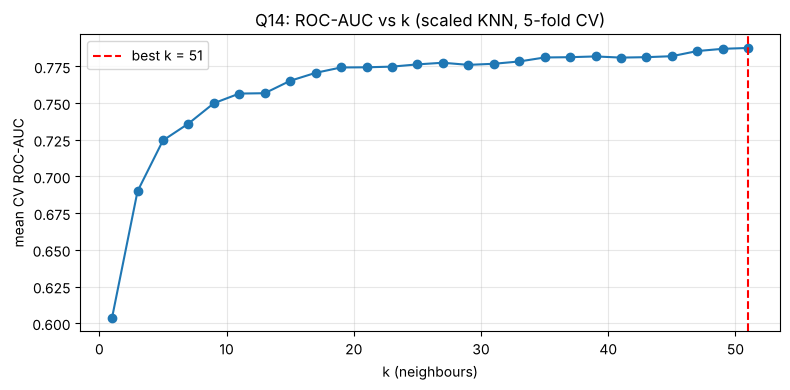

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
ks = list(range(1, 52, 2))
auc = [cross_val_score(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                     KNeighborsClassifier(n_neighbors=k)),
                       X_train[NUM], y_train, cv=cv, scoring='roc_auc').mean() for k in ks]
best_k = ks[int(np.argmax(auc))]
print(pd.Series(auc, index=ks).round(4).to_string())
print('Best k:', best_k, 'CV ROC-AUC:', round(max(auc), 4))
plt.figure(figsize=(8, 4)); plt.plot(ks, auc, 'o-')
plt.axvline(best_k, color='red', ls='--', label=f'best k = {best_k}')
plt.xlabel('k (neighbours)'); plt.ylabel('mean CV ROC-AUC'); plt.title('Q14: ROC-AUC vs k (scaled KNN, 5-fold CV)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig('partA_q14_k_curve.png', dpi=120); plt.show()

**Q14 — answer / interpretation:** ROC-AUC climbs from **0.60 at k = 1** to **0.788 at k = 51**, the best value on this grid. The curve has mostly flattened by k ≈ 35 but is still creeping up at 51.

- **Small k = low bias, high variance.** With k = 1 the prediction is one past visitor's result, noise included, and the probability can only be 0 or 1, so the ranking is poor.
- **Large k = higher bias, lower variance.** Each prediction averages over a broader, less similar crowd. Taken to the extreme (k = 2,250) everyone gets the base rate of 22.6 % and AUC collapses to 0.5.

This data is noisy (many similar-looking people differ in outcome), so reducing variance keeps paying off past k = 51. That's why Q15 searches further.

## Q15 — Add sex & family_history (one-hot) and grid-search k, weights, p

In [16]:
prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), CAT))
tuned_pipe = make_pipeline(prep, KNeighborsClassifier())
grid = {'kneighborsclassifier__n_neighbors': list(range(1, 52, 2)) + [61, 71, 81, 101, 121, 151, 201],
        'kneighborsclassifier__weights': ['uniform', 'distance'],
        'kneighborsclassifier__p': [1, 2]}
gs = GridSearchCV(tuned_pipe, grid, scoring='roc_auc', cv=cv, n_jobs=-1)
gs.fit(X_train[NUM + CAT], y_train)
print('Best params:', gs.best_params_)
print('Best CV ROC-AUC:', round(gs.best_score_, 4))
res = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
print(res[['param_kneighborsclassifier__n_neighbors', 'param_kneighborsclassifier__weights',
           'param_kneighborsclassifier__p', 'mean_test_score']].head(8).to_string(index=False))
best = gs.best_estimator_

Best params: {'kneighborsclassifier__n_neighbors': 151, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'uniform'}
Best CV ROC-AUC: 0.8133
 param_kneighborsclassifier__n_neighbors param_kneighborsclassifier__weights  param_kneighborsclassifier__p  mean_test_score
                                     151                             uniform                              1         0.813296
                                     151                            distance                              1         0.813176
                                     201                            distance                              2         0.811315
                                     201                            distance                              1         0.810739
                                     201                             uniform                              2         0.810523
                                     121                            distance                    

**Q15 — answer / interpretation:** Best combination: **k = 151, p = 1 (Manhattan), weights = 'uniform'**, with **CV ROC-AUC = 0.813**.

The top 8 combinations (k between 101 and 201, either weighting, either metric) are all within 0.004 of each other, so this is a plateau rather than a sharp optimum. Adding sex and family history raised CV AUC from 0.788 to 0.813. (I widened the grid past 101 because the first search picked the edge value.)

## Q16 — Tuned model on the test set (threshold 0.5)

In [17]:
m_tu, cm_tu, p_tu = evaluate(best, X_test[NUM + CAT], y_test)
print({k: round(v, 3) for k, v in m_tu.items()})
tn, fp, fn, tp = cm_tu.ravel()
print('Confusion matrix [[TN FP],[FN TP]]:\n', cm_tu)
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

{'accuracy': 0.789, 'precision': 0.8, 'recall': 0.094, 'f1': 0.168, 'roc_auc': 0.805}
Confusion matrix [[TN FP],[FN TP]]:
 [[576   4]
 [154  16]]
TN=576  FP=4  FN=154  TP=16


**Q16 — answer / interpretation:** At 0.5 the tuned model scores accuracy 78.9 %, precision 80 %, **recall 9.4 %**, F1 0.17 and **ROC-AUC 0.805**. The AUC is in line with its CV score of 0.813, so it isn't overfitting.

- **TN = 576**: non-diabetics we correctly didn't test, so no ₹450 was spent on them.
- **FP = 4**: people we tested who came back normal, ₹1,800 of test money spent with no diagnosis.
- **FN = 154**: diabetics we sent home without a test. This is the costly mistake.
- **TP = 16**: diabetics we tested and caught.

## Q17 — Why Camp Location was left out

In [18]:
print(pd.crosstab(df['camp_location'], df[TARGET], normalize='index').round(3)[1].rename('positive rate by camp'))

camp_location
Dombivli    0.218
Kharghar    0.216
Nerul       0.253
Panvel      0.213
Thane       0.254
Vashi       0.207
Name: positive rate by camp, dtype: float64


**Q17 — answer / interpretation:** **Why left out:** a camp is where someone was screened, not a fact about their body. The positive rate barely differs across camps (20.7 %–25.4 %, see above). Six one-hot columns would also dilute the distance on the measurements that matter, and the model has to work at camps that weren't in the pilot.

**For including it:** camps may serve populations that differ in ways we don't measure (diet, income, age mix). Thane and Nerul run about 4 points above Vashi.

**Against:** it adds noise dimensions to every distance, fails on a new camp it has never seen, and means two people with identical measurements could get different decisions purely because of where they live.

## Q18 — Why 0.5 is the wrong cut-off

In [19]:
print(f"Recall at 0.5 = {m_tu['recall']:.1%}: tests ordered = {(p_tu >= .5).sum()} of 750, budget allows 250")

Recall at 0.5 = 9.4%: tests ordered = 20 of 750, budget allows 250


**Q18 — answer / interpretation:** At 0.5 the model orders only **20 tests and catches 16 of 170 diabetics (9.4 % recall)**, leaving 230 of the 250 paid-for tests unused. With a 22.6 % base rate, few visitors ever reach a 50 % predicted risk, so 0.5 maximises accuracy by mostly saying "negative". Missing a diabetic costs far more than a ₹450 test, so the cut-off should come from the **budget** (250 tests), not from 0.5.

## Q19 — Threshold table

In [20]:
COST = 450
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = p_tu >= t; found = int(y_test[sel].sum()); tests = int(sel.sum())
    rows.append(dict(threshold=t, tests_ordered=tests, diabetics_found=found,
                     diabetics_missed=int(y_test.sum()) - found, hit_rate=round(found / tests, 3),
                     cost_per_diabetic_rs=round(tests * COST / found)))
thr_tab = pd.DataFrame(rows); print(thr_tab.to_string(index=False))

 threshold  tests_ordered  diabetics_found  diabetics_missed  hit_rate  cost_per_diabetic_rs
       0.1            592              166                 4     0.280                  1605
       0.2            333              136                34     0.408                  1102
       0.3            169               89                81     0.527                   854
       0.4             53               36               134     0.679                   662
       0.5             20               16               154     0.800                   562


**Q19 — answer / interpretation:** Lowering the threshold finds more diabetics but each one costs more. At 0.2 we'd order 333 tests and catch 136 of 170 (80 %) at ₹1,102 each. At 0.3 we'd order only 169 tests (under budget) and miss 81. The 250-test budget falls between 0.2 and 0.3, at about 0.245 (Q20). The cost per diabetic at 0.5 looks cheap (₹562), but only because we'd barely test anyone.

## Q20 — Top 250 by probability

In [21]:
def top_n_found(p, yv, n=250):
    order = np.argsort(-p, kind='stable')[:n]
    return int(yv.iloc[order].sum()), order

found250, top_idx = top_n_found(p_tu, y_test)
total_pos = int(y_test.sum())
print(f'Top-250 finds {found250} of {total_pos} diabetics ({found250/total_pos:.1%} recall); hit-rate {found250/250:.1%}')
print(f'Random 250 expectation: {250*y_test.mean():.0f} diabetics   →  {found250/(250*y_test.mean()):.1f}× better')
print(f'Cost per diabetic found: ₹{250*COST/found250:,.0f}  vs random ₹{250*COST/(250*y_test.mean()):,.0f}')
print('Probability at rank 250:', round(p_tu[top_idx[-1]], 3))

Top-250 finds 118 of 170 diabetics (69.4% recall); hit-rate 47.2%
Random 250 expectation: 57 diabetics   →  2.1× better
Cost per diabetic found: ₹953  vs random ₹1,985
Probability at rank 250: 0.245


**Q20 — answer / interpretation:** The top 250 contain **118 of the 170 diabetics (69.4 %)**, a 47 % hit rate, against about **57 for a random 250**. That is **2.1× more diabetics for the same money** (₹953 per diabetic vs ₹1,985). The last person in the list has a predicted risk of about 24.5 %.

## Q21 — Model vs the camp's eyeball rule

In [22]:
Xt = X_test
rule = (Xt['age'] >= 45) & (((Xt['sex'] == 'Male') & (Xt['waist_cm'] >= 90)) |
                            ((Xt['sex'] == 'Female') & (Xt['waist_cm'] >= 80)))
n_rule = int(rule.sum()); found_rule = int(y_test[rule].sum())
found_same_n, _ = top_n_found(p_tu, y_test, n_rule)
cmp = pd.DataFrame({
    'eyeball rule': [n_rule, found_rule, found_rule / n_rule, n_rule * COST / found_rule],
    'KNN top-250': [250, found250, found250 / 250, 250 * COST / found250],
    f'KNN top-{n_rule} (same #tests as rule)': [n_rule, found_same_n, found_same_n / n_rule, n_rule * COST / found_same_n]},
    index=['tests', 'diabetics found', 'hit-rate', 'cost per diabetic ₹']).round(3)
print(cmp)
print('(Rule treats missing age/waist as "not tested":', int((Xt['age'].isna() | Xt['waist_cm'].isna()).sum()), 'people affected)')

                     eyeball rule  KNN top-250  KNN top-350 (same #tests as rule)
tests                     350.000      250.000                            350.000
diabetics found           118.000      118.000                            139.000
hit-rate                    0.337        0.472                              0.397
cost per diabetic ₹      1334.746      953.390                           1133.094
(Rule treats missing age/waist as "not tested": 32 people affected)


**Q21 — answer / interpretation:** The eyeball rule needs **350 tests**, 100 more than the budget allows, and finds **118** diabetics. The model finds the **same 118 with only 250 tests**: **₹953 per diabetic vs ₹1,335**, about 29 % cheaper.

Given the same 350 tests, the model would find 139 vs 118. The rule also silently skips the 32 test visitors with a missing age or waist value, which the model handles through imputation. **The model wins on diabetics per ₹.**

## Q22 — Explain one prediction with its actual neighbours

In [23]:
pos = top_idx[0]                                   # highest-ranked test visitor
visitor = X_test.iloc[[pos]]
print('Visitor:', visitor.index[0], f'P(diabetic) = {p_tu[pos]:.2f}   actual = {y_test.iloc[pos]}')
print(visitor[NUM + CAT].to_string())
knn_step = best[-1]
dist, ind = knn_step.kneighbors(best[:-1].transform(visitor[NUM + CAT]))
nb = X_train.iloc[ind[0]][NUM + CAT].copy()
nb['hba1c'] = y_train.iloc[ind[0]].values; nb['distance'] = dist[0].round(3)
print(f'\nClosest 10 of its {len(nb)} training neighbours:'); print(nb.head(10).to_string())
print('\nAverage of all neighbours:'); print(nb[NUM + ['family_history', 'hba1c']].mean().round(2).to_string())
print(f'\n{nb.hba1c.sum()} of {len(nb)} neighbours were diabetic')

Visitor: 1842 P(diabetic) = 0.66   actual = 1
       age   bmi  waist_cm  daily_steps  systolic  diastolic  total_cholesterol   sex  family_history
1842  69.0  33.6     113.0        590.0     140.0       87.0              243.0  Male               1

Closest 10 of its 151 training neighbours:
       age   bmi  waist_cm  daily_steps  systolic  diastolic  total_cholesterol   sex  family_history  hba1c  distance
956   55.0  31.0     112.0       2650.0     134.0       77.0              248.0  Male               1      1     4.097
2514  61.0  32.6     115.0       1480.0     150.0       89.0              222.0  Male               0      1     4.924
1904  64.0  36.6     117.0       7090.0     138.0       78.0              235.0  Male               1      1     4.958
293   66.0  34.4     119.0       3280.0     134.0       87.0              214.0  Male               0      1     5.287
503   66.0  28.0     102.0        300.0     130.0       76.0              221.0  Male               1      1   

**Q22 — answer / interpretation:** This visitor is a 69-year-old man with BMI 33.6, waist 113 cm, about 590 steps a day, BP 140/87, cholesterol 243 and a family history of diabetes. **100 of his 151 nearest past visitors (66 %) were diabetic**, which is three times the 22.6 % base rate. His ten closest neighbours are all older, heavy-waisted, low-activity men, and all ten were positive.

*What a volunteer could say:* "We compared your measurements with about 150 people from last year's camps who looked most like you: older, more weight around the waist, not very active, with higher blood pressure and cholesterol. About two out of three of them turned out to have diabetes, so we'd like to confirm with the blood test today." 

## Q23 — The visitor ranked 260th

In [24]:
order = np.argsort(-p_tu, kind='stable')
r250, r260 = order[249], order[259]
print(pd.DataFrame({'rank 250 (last tested)': X_test.iloc[r250][NUM + CAT],
                    'rank 260 (not tested)': X_test.iloc[r260][NUM + CAT]}))
print(f'P(diabetic): rank 250 = {p_tu[r250]:.3f}, rank 260 = {p_tu[r260]:.3f}')

                  rank 250 (last tested) rank 260 (not tested)
age                                 37.0                  41.0
bmi                                 27.5                  23.1
waist_cm                            97.0                  81.0
daily_steps                       5770.0                7640.0
systolic                           121.0                 148.0
diastolic                           82.0                  96.0
total_cholesterol                  200.0                 132.0
sex                               Female                Female
family_history                         1                     1
P(diabetic): rank 250 = 0.245, rank 260 = 0.238


**Q23 — answer / interpretation:** *Suggested reply:* "You and your friend may weigh the same, but the screening doesn't look at weight alone. It compares nine things together: age, BMI, waist, daily activity, blood pressure, cholesterol, sex and family history. It then asks how much your whole pattern resembles last year's visitors who turned out to be diabetic. Your friend's pattern was slightly closer. Honestly, it was very close: your estimated risk was about 24 %, and the last person tested was at 24.5 %. The cut-off is set by how many tests the grant pays for, not by a medical line, so being just outside it does **not** mean you're in the clear. If you have symptoms or are worried, please ask your doctor for an HbA1c, and you're welcome at the next camp." 

## Q24 — Summary table

In [25]:
summary = pd.DataFrame({
    'raw KNN (k=5)': [m_raw['accuracy'], m_raw['recall'], m_raw['roc_auc'], top_n_found(p_raw, y_test)[0]],
    'scaled KNN (k=5)': [m_sc['accuracy'], m_sc['recall'], m_sc['roc_auc'], top_n_found(p_sc, y_test)[0]],
    'tuned KNN': [m_tu['accuracy'], m_tu['recall'], m_tu['roc_auc'], found250]},
    index=['accuracy', 'recall @0.5', 'ROC-AUC', 'diabetics in top 250']).round(3)
print(summary)

                      raw KNN (k=5)  scaled KNN (k=5)  tuned KNN
accuracy                      0.763             0.788      0.789
recall @0.5                   0.176             0.341      0.094
ROC-AUC                       0.656             0.723      0.805
diabetics in top 250         81.000            99.000    118.000


**Q24 — answer / interpretation:** The ranking is what matters here, and it improves at every step: **81 → 99 → 118 diabetics in the top 250**, with ROC-AUC 0.656 → 0.723 → 0.805. The tuned model has the *lowest* recall at 0.5 (9.4 %), because with k = 151 its probabilities rarely reach 0.5. That number is irrelevant once we cut at the budget instead. Raw accuracy also hides the raw model's failure, since 76 % is below the do-nothing baseline.

## Q25 — Recommendation to the CSR programme manager

**Q25 — answer / interpretation:** **Recommendation: yes, use it as the triage tool, with two safeguards.**

On the day, volunteers enter the free measurements into a tablet form. Each visitor gets a risk score, and at the end of each session the top third by score are sent for HbA1c, which works out to roughly a 24–25 % predicted-risk cut-off.

On the pilot data, 250 tests find **118 diabetics**, against about **57 for a random pick** and about **84 for today's eyeball rule** at the same 250 tests (33.7 % hit rate). That is **roughly 34 more diabetics per 250 tests**, and ₹953 per diabetic instead of ₹1,335.

It still misses about 30 % of diabetics, so everyone outside the budget should get a printed referral rather than reassurance.

**The risk to watch is who the pilot covered.** It included six urban Navi Mumbai/Thane camps, people who chose to attend, and mostly people with a phone that tracks steps. Rural visitors, young adults, or people without smartphones (whose steps get imputed as the median) will be compared against neighbours unlike them, so re-check the model each quarter by testing a small random sample.